# E-commerce Landing Page A/B Test — Analysis

## Pre-registration (written 2026-10-22, before any test results were computed)

**Question:** Does the new landing page change the conversion rate compared with the old page?

| Item | Decision |
|---|---|
| Primary metric | Conversion rate = converted users ÷ users, per group |
| Hypotheses | H0: p_treatment = p_control  ·  H1: p_treatment ≠ p_control |
| Test | Two-proportion z-test, **two-sided**, with a 95% CI for the difference (treatment − control) |
| Significance level | **alpha = 0.05** |
| Main analysis | `ab_dbt.int_ab_users_clean` — 286,690 users; every user appearing more than once in raw is excluded (they may have seen both pages) |
| Sensitivity check | `ab_dbt.int_ab_users_sensitivity` — 290,584 users; mismatched rows dropped, each user's first remaining event kept. Reported alongside the main result, stating whether the conclusion changes |
| Validity check first | Sample ratio mismatch (SRM): chi-square test against a 50/50 split. If p < 0.01, randomization is suspect and the result is not trusted |

**What had been seen before writing this:** row and user counts per group, and the *raw, pre-cleaning*
conversion rates from data profiling on 2026-10-21 (control 12.04%, treatment 11.89%). No conversion rates
or test statistics had been computed on either cleaned table.


## 6a. Pull the clean data

Both user tables come from the dbt models in BigQuery. Before going further, check they match the counts
dbt verified: one row per user, and the expected users per group. Only user counts are shown here;
conversion rates are first computed in 6c.

In [1]:
from google.cloud import bigquery
import pandas as pd

PROJECT = "ab-test-portfolio-512322"
client = bigquery.Client(project=PROJECT)


def load(table):
    sql = f"SELECT * FROM `{PROJECT}.ab_dbt.{table}`"
    return client.query(sql).to_dataframe(create_bqstorage_client=False)


clean = load("int_ab_users_clean")
sens = load("int_ab_users_sensitivity")

# Sanity checks against the dbt-verified counts (users only, no conversion rates yet).
EXPECTED = {
    "clean": {"control": 143_293, "treatment": 143_397},
    "sensitivity": {"control": 145_274, "treatment": 145_310},
}
for name, df in [("clean", clean), ("sensitivity", sens)]:
    users = df["experiment_group"].value_counts().sort_index()
    assert df["user_id"].is_unique, f"{name}: duplicate user_id"
    assert users.to_dict() == EXPECTED[name], f"{name}: {users.to_dict()}"
    print(f"{name:<12} users={len(df):,}  " + "  ".join(f"{g}={n:,}" for g, n in users.items()))

clean        users=286,690  control=143,293  treatment=143,397
sensitivity  users=290,584  control=145,274  treatment=145,310


In [2]:
# Data-quality counts behind the cleaning decision, from the staging view (all raw rows).
dq = client.query(f"""
WITH per_user AS (
  SELECT user_id, COUNT(*) AS n_rows, COUNTIF(is_assignment_mismatch) AS n_mismatch
  FROM `{PROJECT}.ab_dbt.stg_ab_events`
  GROUP BY user_id
)
SELECT
  SUM(n_rows)                              AS raw_rows,
  COUNT(*)                                 AS raw_users,
  COUNTIF(n_rows > 1)                      AS repeat_users,
  SUM(n_mismatch)                          AS mismatched_rows,
  COUNTIF(n_rows > 1 AND n_mismatch > 0)   AS repeat_users_with_mismatch,
  SUM(IF(n_rows = 1, n_mismatch, 0))       AS mismatched_rows_from_single_row_users
FROM per_user
""").to_dataframe(create_bqstorage_client=False).iloc[0]

assert dq["repeat_users"] == 3_894 and dq["mismatched_rows"] == 3_893, dq.to_dict()
for name, value in dq.items():
    print(f"{name:<40} {int(value):,}")

raw_rows                                 294,478
raw_users                                290,584
repeat_users                             3,894
mismatched_rows                          3,893
repeat_users_with_mismatch               3,893
mismatched_rows_from_single_row_users    0


## 6b. Sample ratio mismatch (SRM) check

Users were meant to be split 50/50. A chi-square test compares the observed group sizes with a perfect
50/50 split. Per the pre-registration, p < 0.01 means randomization is suspect and the result is not trusted.

In [3]:
from scipy.stats import chisquare

SRM_ALPHA = 0.01


def srm_check(name, df):
    obs = df["experiment_group"].value_counts().sort_index()
    stat, p = chisquare(obs.values, [obs.sum() / 2] * 2)
    share = obs["treatment"] / obs.sum()
    verdict = "SRM detected" if p < SRM_ALPHA else "no SRM"
    print(
        f"{name:<12} control={obs['control']:,}  treatment={obs['treatment']:,}  "
        f"diff={obs['treatment'] - obs['control']:+,}  treatment share={share:.3%}  "
        f"chi2={stat:.4f}  p={p:.4f}  -> {verdict}"
    )


srm_check("clean", clean)
srm_check("sensitivity", sens)

clean        control=143,293  treatment=143,397  diff=+104  treatment share=50.018%  chi2=0.0377  p=0.8460  -> no SRM
sensitivity  control=145,274  treatment=145,310  diff=+36  treatment share=50.006%  chi2=0.0045  p=0.9468  -> no SRM


**SRM result: no sample ratio mismatch.** Treatment holds 50.018% of users in the main table
(+104 users, p = 0.846) and 50.006% in the sensitivity table (+36 users, p = 0.947), both far above the
pre-registered 0.01 threshold. A gap this small is what random assignment alone produces, so the split
looks healthy and the comparison in 6c can be trusted on this check. Excluding the 3,894 repeat users
did not unbalance the groups.

## 6c. Two-proportion z-test and 95% CI (pre-registered: two-sided, alpha = 0.05)

Main analysis on `int_ab_users_clean` first, then the sensitivity check on `int_ab_users_sensitivity`.
Lift is treatment − control. The CI is for that difference (Newcombe method, statsmodels default).

In [4]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ALPHA = 0.05


def ab_test(name, df):
    g = df.groupby("experiment_group")["converted"].agg(conversions="sum", users="count")
    c_conv, c_n = int(g.loc["control", "conversions"]), int(g.loc["control", "users"])
    t_conv, t_n = int(g.loc["treatment", "conversions"]), int(g.loc["treatment", "users"])
    c_rate, t_rate = c_conv / c_n, t_conv / t_n

    z, p = proportions_ztest([t_conv, c_conv], [t_n, c_n], alternative="two-sided")
    low, high = confint_proportions_2indep(
        t_conv, t_n, c_conv, c_n, compare="diff", alpha=ALPHA
    )
    abs_lift = t_rate - c_rate

    print(f"== {name} ==")
    print(f"control:    {c_conv:,} / {c_n:,} = {c_rate:.4%}")
    print(f"treatment:  {t_conv:,} / {t_n:,} = {t_rate:.4%}")
    print(f"absolute lift:  {abs_lift * 100:+.3f} percentage points")
    print(f"relative lift:  {abs_lift / c_rate:+.2%}")
    print(f"z = {z:.3f}, p = {p:.4f}  -> {'significant' if p < ALPHA else 'not significant'} at alpha {ALPHA}")
    print(f"95% CI for difference: [{low * 100:+.3f}, {high * 100:+.3f}] percentage points\n")
    return {
        "control_users": c_n, "treatment_users": t_n,
        "control_rate": c_rate, "treatment_rate": t_rate,
        "abs_lift_pts": abs_lift * 100, "rel_lift": abs_lift / c_rate,
        "z": z, "p": p, "ci_low_pts": low * 100, "ci_high_pts": high * 100,
    }


results = {"clean (main)": ab_test("clean (main)", clean)}
results["sensitivity"] = ab_test("sensitivity", sens)
summary = pd.DataFrame(results).T
summary[["control_users", "treatment_users"]] = summary[["control_users", "treatment_users"]].astype(int)
summary.round(4)

== clean (main) ==
control:    17,220 / 143,293 = 12.0173%
treatment:  17,025 / 143,397 = 11.8726%
absolute lift:  -0.145 percentage points
relative lift:  -1.20%
z = -1.194, p = 0.2323  -> not significant at alpha 0.05
95% CI for difference: [-0.382, +0.093] percentage points

== sensitivity ==
control:    17,489 / 145,274 = 12.0386%
treatment:  17,264 / 145,310 = 11.8808%
absolute lift:  -0.158 percentage points
relative lift:  -1.31%
z = -1.311, p = 0.1899  -> not significant at alpha 0.05
95% CI for difference: [-0.394, +0.078] percentage points



,control_users,treatment_users,control_rate,treatment_rate,abs_lift_pts,rel_lift,z,p,ci_low_pts,ci_high_pts
clean (main),143293,143397,0.1202,0.1187,-0.1447,-0.0120,-1.1945,0.2323,-0.3821,0.0927
sensitivity,145274,145310,0.1204,0.1188,-0.1578,-0.0131,-1.3109,0.1899,-0.3938,0.0781


## 6d. Was the test powered to detect a meaningful effect?

Minimum detectable effect (MDE): the smallest true lift this test had an 80% chance of detecting
(two-sided, alpha = 0.05) with the group sizes we actually have. Then: users per group needed to detect
absolute lifts of +0.5, +1 and +2 points from the control baseline.

In [5]:
import numpy as np
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

POWER = 0.80
power_calc = NormalIndPower()


def mde_pts(baseline, n_t, n_c):
    # Solve for Cohen's h, then convert back to an absolute lift above the baseline.
    h = power_calc.solve_power(
        effect_size=None, nobs1=n_t, ratio=n_c / n_t, alpha=ALPHA, power=POWER, alternative="two-sided"
    )
    return (np.sin(np.arcsin(np.sqrt(baseline)) + h / 2) ** 2 - baseline) * 100


for name, r in results.items():
    mde = mde_pts(r["control_rate"], r["treatment_users"], r["control_users"])
    print(
        f"{name:<13} MDE at 80% power: {mde:.3f} points "
        f"({mde / 100 / r['control_rate']:.1%} relative) with ~{r['control_users']:,} users per group"
    )

main = results["clean (main)"]
baseline = main["control_rate"]
print(f"\nUsers per group needed (baseline = control rate {baseline:.4%}):")
for lift in [0.005, 0.01, 0.02]:
    es = proportion_effectsize(baseline + lift, baseline)
    n = power_calc.solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
    have = min(main["control_users"], main["treatment_users"])
    print(f"  +{lift * 100:.1f} points: {n:>8,.0f} per group  (we have {have:,}: {have / n:.1f}x)")

clean (main)  MDE at 80% power: 0.342 points (2.8% relative) with ~143,293 users per group
sensitivity   MDE at 80% power: 0.340 points (2.8% relative) with ~145,274 users per group

Users per group needed (baseline = control rate 12.0173%):
  +0.5 points:   67,572 per group  (we have 143,293: 2.1x)
  +1.0 points:   17,183 per group  (we have 143,293: 8.3x)
  +2.0 points:    4,438 per group  (we have 143,293: 32.3x)


**Interpretation (6c + 6d)**

- **Result:** treatment converted at 11.87% vs 12.02% for control, a lift of −0.145 points (−1.2% relative),
  z = −1.19, p = 0.232. Not significant at the pre-registered alpha of 0.05.
- **No effect, or test too small?** The test was **not** too small. With ~143k users per group it had 80%
  power to detect a lift as small as **0.34 points** (2.8% relative), and it had 2–32x the users needed to
  detect +0.5, +1 or +2 points. The 95% CI of **[−0.38, +0.09] points** rules out any improvement larger
  than about +0.09 points. So the data does not prove the effect is exactly zero, but it rules out any
  improvement big enough to matter; the best estimate is slightly negative.
- **Sensitivity check agrees:** keeping the repeat users gives −0.158 points, p = 0.190, CI [−0.39, +0.08].
  Same direction, similar size, same conclusion. Excluding repeat users did not drive the result.

## 6e. Novelty effect check

If users react to the new page just because it's new, treatment would start strong and fade. Two views
from `fct_daily_conversion`: daily conversion rate per group, and the daily difference (treatment − control)
with a 95% band. Then the lift by period of the test, and a weighted trend line through the daily differences.
Jan 2 and Jan 24 are partial days (hollow markers).

saved /Users/DevarshiDave/Desktop/ecommerce-ab-test-analysis/images/daily_conversion.png


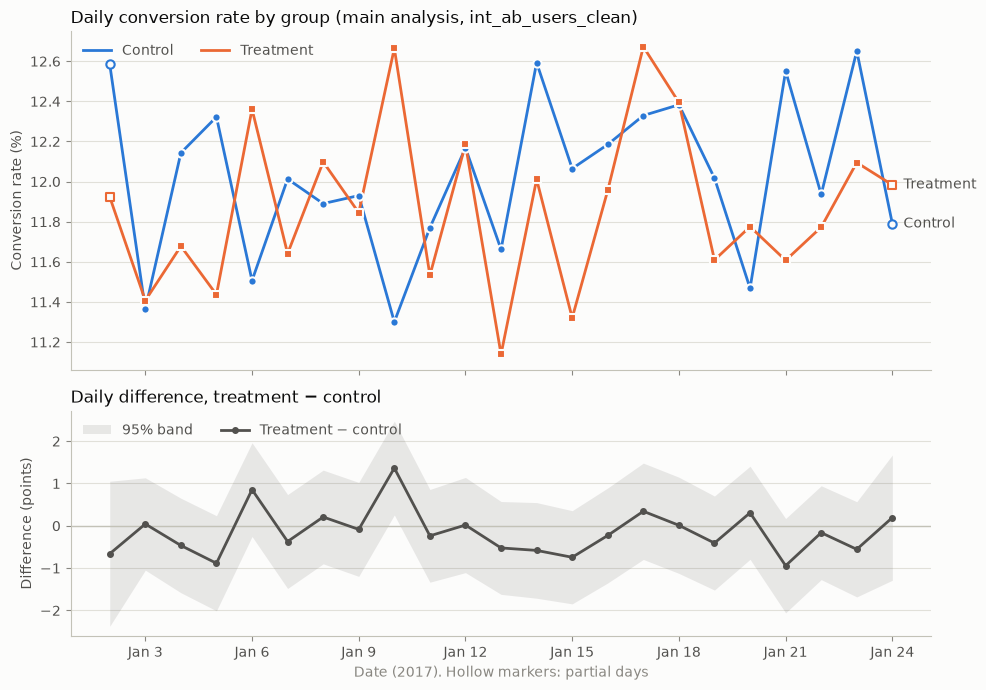

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

daily = client.query(
    f"SELECT * FROM `{PROJECT}.ab_dbt.fct_daily_conversion` ORDER BY event_date"
).to_dataframe(create_bqstorage_client=False)
daily["event_date"] = pd.to_datetime(daily["event_date"])
assert len(daily) == 46, len(daily)

wide = daily.pivot(index="event_date", columns="experiment_group", values=["users", "conversions"]).astype(float)
users, conv = wide["users"], wide["conversions"]
rate = conv / users
diff_pts = (rate["treatment"] - rate["control"]) * 100
se_pts = np.sqrt(
    rate["treatment"] * (1 - rate["treatment"]) / users["treatment"]
    + rate["control"] * (1 - rate["control"]) / users["control"]
) * 100
is_partial = rate.index.isin([rate.index.min(), rate.index.max()])

# Reference palette: categorical slots 1-2, light chart surface and ink.
COLORS = {"control": "#2a78d6", "treatment": "#eb6834"}
MARKERS = {"control": "o", "treatment": "s"}
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}, facecolor=SURFACE
)
for ax in (ax1, ax2):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelcolor=INK_2)

for group in ["control", "treatment"]:
    y = rate[group] * 100
    ax1.plot(y.index, y, color=COLORS[group], linewidth=2, label=group.capitalize(), zorder=2)
    ax1.scatter(y.index[~is_partial], y[~is_partial], color=COLORS[group], marker=MARKERS[group],
                s=36, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax1.scatter(y.index[is_partial], y[is_partial], facecolor=SURFACE, edgecolor=COLORS[group],
                marker=MARKERS[group], s=36, linewidth=1.5, zorder=3)
    ax1.annotate(group.capitalize(), (y.index[-1], y.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                 va="center", color=INK_2, fontsize=10)
ax1.set_ylabel("Conversion rate (%)", color=INK_2)
ax1.set_title("Daily conversion rate by group (main analysis, int_ab_users_clean)", loc="left", color=INK, fontsize=12)
ax1.legend(frameon=False, loc="upper left", labelcolor=INK_2, ncol=2)

ax2.axhline(0, color=BASELINE, linewidth=1)
ax2.fill_between(diff_pts.index, diff_pts - 1.96 * se_pts, diff_pts + 1.96 * se_pts,
                 color=INK_2, alpha=0.12, linewidth=0, label="95% band")
ax2.plot(diff_pts.index, diff_pts, color=INK_2, linewidth=2, marker="o", markersize=4, label="Treatment − control")
ax2.set_ylabel("Difference (points)", color=INK_2)
ax2.set_title("Daily difference, treatment − control", loc="left", color=INK, fontsize=12)
ax2.legend(frameon=False, loc="upper left", labelcolor=INK_2, ncol=2)
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %-d"))
ax2.set_xlabel("Date (2017). Hollow markers: partial days", color=MUTED)

fig.tight_layout()
out = Path("..") / "images" / "daily_conversion.png"
fig.savefig(out, dpi=200, facecolor=SURFACE)
print(f"saved {out.resolve()}")
plt.show()

In [7]:
import statsmodels.api as sm

# Lift by period of the test (main analysis), pooled from the daily mart.
day_num = (daily["event_date"] - daily["event_date"].min()).dt.days + 1
daily["period"] = pd.cut(day_num, [0, 7, 15, 23], labels=["Jan 2-8", "Jan 9-16", "Jan 17-24"])
p = daily.groupby(["period", "experiment_group"], observed=True)[["users", "conversions"]].sum().unstack().astype(float)
p_rate = p["conversions"] / p["users"]
period_diff = (p_rate["treatment"] - p_rate["control"]) * 100
period_se = np.sqrt(
    p_rate["treatment"] * (1 - p_rate["treatment"]) / p["users"]["treatment"]
    + p_rate["control"] * (1 - p_rate["control"]) / p["users"]["control"]
) * 100
periods = pd.DataFrame({
    "users_per_group": p["users"].min(axis=1).astype(int),
    "lift_pts": period_diff.round(3),
    "ci_low_pts": (period_diff - 1.96 * period_se).round(3),
    "ci_high_pts": (period_diff + 1.96 * period_se).round(3),
})
print(periods.to_string(), "\n")

# Trend: weighted least squares of the daily difference on day number (weights = 1 / variance).
X = sm.add_constant(np.arange(len(diff_pts)))
trend = sm.WLS(diff_pts.values, X, weights=1 / se_pts.values ** 2).fit()
slope, slope_p = trend.params[1], trend.pvalues[1]
print(f"trend in daily difference: {slope:+.4f} points per day "
      f"({slope * 22:+.3f} points over the 22 days), p = {slope_p:.3f}")

           users_per_group  lift_pts  ci_low_pts  ci_high_pts
period                                                       
Jan 2-8              41731    -0.135      -0.573        0.303
Jan 9-16             52135    -0.123      -0.516        0.270
Jan 17-24            49248    -0.175      -0.582        0.232 

trend in daily difference: -0.0103 points per day (-0.227 points over the 22 days), p = 0.580


**Interpretation (6e): no novelty effect and no trend.**

- **Treatment never started strong.** Its lift was −0.135 points in the first week (Jan 2–8), −0.123 in
  Jan 9–16 and −0.175 in Jan 17–24. All three are slightly negative, every period's 95% CI includes zero,
  and the three estimates sit close to the overall −0.145.
- **No drift over time.** The weighted trend in the daily difference is −0.010 points per day, p = 0.580:
  indistinguishable from flat.
- **Day-to-day swings are noise.** Each day has only ~3–7k users per group, so daily rates bounce by
  ±0.5–1 point. Only one day of 23 (Jan 10, +1.35 points) has a band entirely above zero, about what chance
  alone produces at 95% confidence over 23 days.
- **Implication:** the flat-to-slightly-negative result in 6c is not the average of an early boost and a
  later fade. Running the test longer would not be expected to change the conclusion.

# A/B Test Results Memo

**1. Decision.** We should not ship the new page. It shows no meaningful conversion improvement over the existing page.

**2. What was tested.** We compared the old and new pages from January 2–24, 2017, analyzing 286,690 users: 143,293 control and 143,397 treatment.

**3. Data quality.** We removed 3,894 repeat users, including 3,893 with a row assigned to the wrong group, because they may have seen both pages. The sample-ratio mismatch check passed (p = 0.85), confirming a fair group split.

**4. Result.** Conversion was 12.02% for control versus 11.87% for treatment, a −0.14-point difference—about 14 fewer conversions per 10,000 visitors. The 95% confidence range (−0.38 to +0.09 points) and p-value (0.23) indicate no statistically significant difference.

**5. Why it’s a real answer.** The test could detect a lift of just 0.34 points, and the confidence range rules out gains above 0.09 points. If the new page helped by any amount worth shipping, this test would very likely have detected it.

**6. Robustness.** Including repeat users gives the same conclusion (−0.16 points, p = 0.19). Results were slightly negative in all three weeks, with no sign of a novelty effect.

**7. Next step.** Keep the old page and test a different improvement, such as pricing presentation or checkout design.